# 01 — Exploratory Data Analysis: Give Me Some Credit

**Goal:** understand the data before modelling: missing values, outliers, the target distribution
(`SeriousDlqin2yrs`) and how each variable relates to default.

**Important:** the EDA is run on the **training split only** (80%). The 20% test set is created
here with the same function used in training (`src.data.split_train_test`, fixed seed) and is not
looked at. Every cleaning decision taken from this notebook is therefore free of test-set leakage.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import TARGET, load_raw, split_train_test

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

df = load_raw()
train, test = split_train_test(df)
print(f"Full data: {df.shape}, train: {train.shape}, test (untouched): {test.shape}")
train.head()

Full data: (150000, 11), train: (120000, 11), test (untouched): (30000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
id,,,,,,,,,,,
57837,0,0.1150,62,0,"1,841.0000",NaN,5,0,1,0,2.0000
132896,0,0.0087,73,0,0.4986,"3,800.0000",6,0,1,0,0.0000
27982,0,0.2145,32,0,0.2120,"3,716.0000",8,0,0,0,2.0000
37853,0,1.0000,60,0,118.0000,NaN,5,0,0,0,0.0000
103814,0,0.2305,60,0,1.0173,"3,000.0000",10,0,1,0,0.0000


## 1. Variables

| Column | Meaning |
|---|---|
| `SeriousDlqin2yrs` | **Target**: 90+ days past due in the next 2 years (1 = default) |
| `RevolvingUtilizationOfUnsecuredLines` | Balance on credit cards / personal lines divided by their limits |
| `age` | Borrower age in years |
| `NumberOfTime30-59DaysPastDueNotWorse` | Times 30–59 days late in the last 2 years |
| `NumberOfTime60-89DaysPastDueNotWorse` | Times 60–89 days late in the last 2 years |
| `NumberOfTimes90DaysLate` | Times 90+ days late |
| `DebtRatio` | Monthly debt payments + living costs divided by monthly gross income |
| `MonthlyIncome` | Monthly income |
| `NumberOfOpenCreditLinesAndLoans` | Open loans and credit lines |
| `NumberRealEstateLoansOrLines` | Mortgage and real estate loans |
| `NumberOfDependents` | Dependents in the family, excluding the borrower |

In [2]:
train.info()

<class 'pandas.DataFrame'>
Index: 120000 entries, 57837 to 80531
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      120000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  120000 non-null  float64
 2   age                                   120000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  120000 non-null  int64  
 4   DebtRatio                             120000 non-null  float64
 5   MonthlyIncome                         96325 non-null   float64
 6   NumberOfOpenCreditLinesAndLoans       120000 non-null  int64  
 7   NumberOfTimes90DaysLate               120000 non-null  int64  
 8   NumberRealEstateLoansOrLines          120000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  120000 non-null  int64  
 10  NumberOfDependents                    116872 non-null  float64
dtypes: float64(4)

## 2. Target distribution

SeriousDlqin2yrs
0    111979
1      8021
Default rate (train): 6.6842%  |  test: 6.6833%


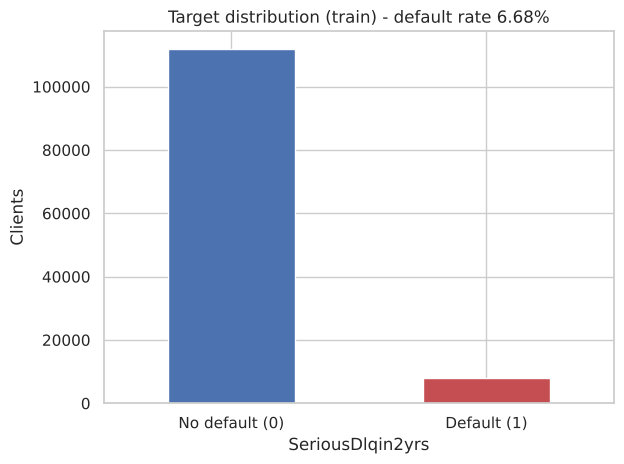

In [3]:
counts = train[TARGET].value_counts().sort_index()
rate = train[TARGET].mean()
print(counts.to_string())
print(f"Default rate (train): {rate:.4%}  |  test: {test[TARGET].mean():.4%}")

ax = counts.plot.bar(color=["#4C72B0", "#C44E52"])
ax.set_xticklabels(["No default (0)", "Default (1)"], rotation=0)
ax.set_title(f"Target distribution (train) - default rate {rate:.2%}")
ax.set_ylabel("Clients")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_target.png", dpi=120); plt.show()

**Conclusion.** About 6.7% of clients default, so the classes are imbalanced roughly 1:14. A model
that always predicts "no default" would reach ~93% accuracy while being useless, which is why
accuracy is not the main metric. The project uses ranking metrics (AUC-ROC, Gini, KS) and the
precision-recall curve, and the split is stratified so train and test keep the same default rate.

## 3. Missing values

In [4]:
missing = pd.DataFrame({"missing": train.isna().sum(), "pct": train.isna().mean()})
missing = missing[missing["missing"] > 0]
print(missing)

for col in missing.index:
    is_na = train[col].isna()
    print(f"{col}: default rate when missing = {train.loc[is_na, TARGET].mean():.4f}, "
          f"when present = {train.loc[~is_na, TARGET].mean():.4f}")

both = (train["MonthlyIncome"].isna() & train["NumberOfDependents"].isna()).sum()
print(f"Rows missing NumberOfDependents that also miss MonthlyIncome: "
      f"{both} of {train['NumberOfDependents'].isna().sum()}")

                    missing    pct
MonthlyIncome         23675 0.1973
NumberOfDependents     3128 0.0261
MonthlyIncome: default rate when missing = 0.0557, when present = 0.0696
NumberOfDependents: default rate when missing = 0.0441, when present = 0.0674
Rows missing NumberOfDependents that also miss MonthlyIncome: 3128 of 3128


In [5]:
inc_na = train["MonthlyIncome"].isna()
print("DebtRatio when income is missing:")
print(train.loc[inc_na, "DebtRatio"].describe())
print("\nDebtRatio when income is present:")
print(train.loc[~inc_na, "DebtRatio"].describe())

DebtRatio when income is missing:
count    23,675.0000
mean      1,682.0921
std       4,427.9096
min           0.0000
25%         123.0000
50%       1,163.0000
75%       2,384.0000
max     329,664.0000
Name: DebtRatio, dtype: float64

DebtRatio when income is present:
count   96,325.0000
mean        25.4245
std        317.5110
min          0.0000
25%          0.1440
50%          0.2961
75%          0.4828
max     25,801.0000
Name: DebtRatio, dtype: float64


**Conclusion.**

- `MonthlyIncome` is missing for ~20% of clients and `NumberOfDependents` for ~2.6%. Every row
  missing dependents also misses income, so it looks like one data-collection gap, not random noise.
- Missingness is **informative**: clients without reported income default *less* (~5.6% vs ~7.0%).
  Dropping those rows would discard 20% of the data and bias the sample, so instead we impute with
  the median (robust to the very skewed income) **and add a binary flag** `MonthlyIncome_missing`
  so the model can still use the fact that income was not reported.
- When income is missing, `DebtRatio` has a median above 1,000 instead of ~0.3. That means the
  ratio was computed without a real denominator: it holds an absolute debt amount, not a ratio.
  `DebtRatio` is therefore not comparable between the two groups, which the missing flag lets the
  model separate.

## 4. Outliers and suspicious values

In [6]:
train.describe(percentiles=[0.01, 0.5, 0.95, 0.99, 0.999]).T

,count,mean,std,min,1%,50%,95%,99%,99.9%,max
SeriousDlqin2yrs,"120,000.0000",0.0668,0.2497,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,1.0000
RevolvingUtilizationOfUnsecuredLines,"120,000.0000",6.1289,253.3615,0.0000,0.0000,0.1533,1.0000,1.0944,"1,655.0040","50,708.0000"
age,"120,000.0000",52.2878,14.7713,0.0000,24.0000,52.0000,78.0000,87.0000,93.0010,109.0000
NumberOfTime30-59DaysPastDueNotWorse,"120,000.0000",0.4201,4.1821,0.0000,0.0000,0.0000,2.0000,4.0000,98.0000,98.0000
DebtRatio,"120,000.0000",352.2712,"2,093.7095",0.0000,0.0000,0.3662,"2,441.0000","4,977.0000","10,613.0740","329,664.0000"
MonthlyIncome,"96,325.0000","6,651.5073","14,541.1814",0.0000,0.0000,"5,390.0000","14,584.8000","25,000.0000","77,764.7760","3,008,750.0000"
NumberOfOpenCreditLinesAndLoans,"120,000.0000",8.4657,5.1617,0.0000,0.0000,8.0000,18.0000,25.0000,35.0000,58.0000
NumberOfTimes90DaysLate,"120,000.0000",0.2649,4.1582,0.0000,0.0000,0.0000,1.0000,3.0000,98.0000,98.0000
NumberRealEstateLoansOrLines,"120,000.0000",1.0182,1.1331,0.0000,0.0000,1.0000,3.0000,4.0000,9.0000,54.0000
NumberOfTime60-89DaysPastDueNotWorse,"120,000.0000",0.2399,4.1446,0.0000,0.0000,0.0000,1.0000,2.0000,98.0000,98.0000


In [7]:
late_cols = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
]
for col in late_cols:
    print(col, train[col].value_counts().sort_index().tail(6).to_dict())

codes = train[late_cols[0]].isin([96, 98])
print(f"\nRows with 96/98 in the late-payment columns: {codes.sum()}")
print("Same code in all three columns:", (train.loc[codes, late_cols].nunique(axis=1) == 1).all())
print(f"Default rate of those rows: {train.loc[codes, TARGET].mean():.4f}")

NumberOfTime30-59DaysPastDueNotWorse {10: 4, 11: 1, 12: 2, 13: 1, 96: 2, 98: 212}
NumberOfTime60-89DaysPastDueNotWorse {7: 8, 8: 1, 9: 1, 11: 1, 96: 2, 98: 212}
NumberOfTimes90DaysLate {13: 3, 14: 2, 15: 2, 17: 1, 96: 2, 98: 212}

Rows with 96/98 in the late-payment columns: 214
Same code in all three columns: True
Default rate of those rows: 0.5467


In [8]:
ruul = train["RevolvingUtilizationOfUnsecuredLines"]
print(f"Utilization > 1: {(ruul > 1).mean():.2%} of clients, > 10: {(ruul > 10).sum()} clients")
print(train.groupby(pd.cut(ruul, [-0.01, 0.5, 1, 2, 10, np.inf]), observed=True)[TARGET]
      .agg(["mean", "size"]))

print(f"\nage == 0: {(train['age'] == 0).sum()} rows; age < 18: {(train['age'] < 18).sum()} rows")
print(f"Exact duplicate rows in train: {train.duplicated().sum()}")

Utilization > 1: 2.20% of clients, > 10: 190 clients
                                       mean   size
RevolvingUtilizationOfUnsecuredLines              
(-0.01, 0.5]                         0.0274  87020
(0.5, 1.0]                           0.1532  30340
(1.0, 2.0]                           0.4012   2348
(2.0, 10.0]                          0.3039    102
(10.0, inf]                          0.0895    190

age == 0: 1 rows; age < 18: 1 rows


Exact duplicate rows in train: 437


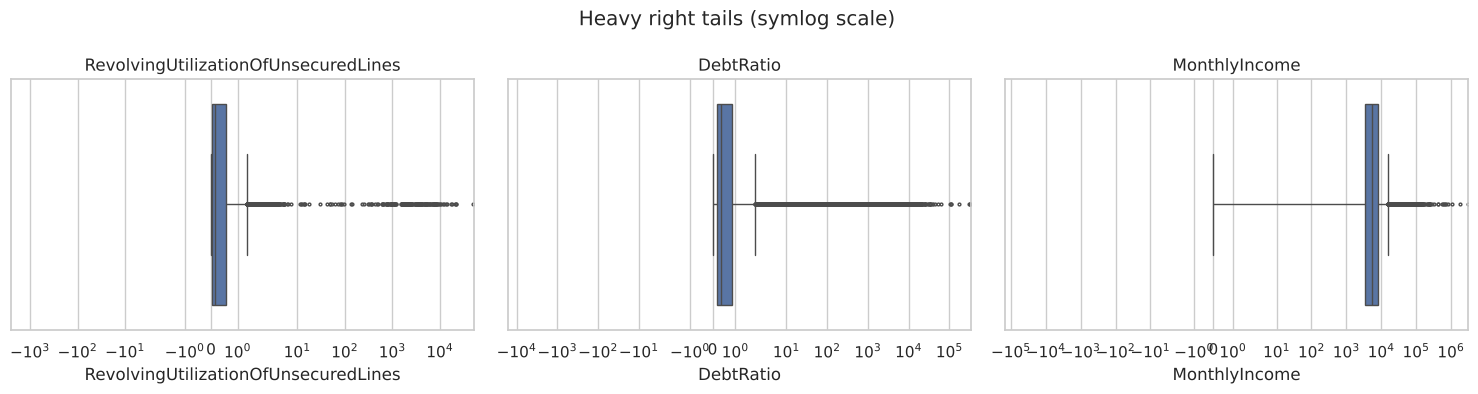

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio", "MonthlyIncome"]):
    sns.boxplot(x=train[col], ax=ax, color="#4C72B0", fliersize=2)
    ax.set_xscale("symlog")
    ax.set_title(col)
plt.suptitle("Heavy right tails (symlog scale)")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_outliers.png", dpi=120); plt.show()

**Conclusion.**

- **Codes 96 and 98** in the three late-payment columns are not real counts (nobody is late 98
  times in 2 years); they appear together in the same ~200 rows and those rows default about
  half the time. They look like special "unknown/administrative" codes. Treatment: replace them
  with a missing value plus a flag, so the information is kept but they do not distort the counts.
- **Revolving utilization** should be between 0 and 1. ~2% of clients are above 1 (over the limit) and ~190
  are above 10, up to ~50,000, which is almost certainly a data error. Utilization
  between 1 and 2 is the riskiest band (~40% default), so values above 1 must not simply be deleted.
  Treatment: cap (winsorize) at a high percentile learned on the training data.
- **DebtRatio** and **MonthlyIncome** have extreme right tails (income up to ~3 million per month).
  Treatment: cap at a high percentile. Trees are insensitive to this, but logistic regression is not.
- **age = 0** appears once: impossible for a borrower, treated as missing and imputed.
- 437 exact duplicate rows exist in train. With only 11 numeric columns, two different clients can share
  identical values, so they are kept.

Caps and medians are computed on the training data inside the scikit-learn pipeline, never on the
test set, to avoid leakage.

## 5. Relationship of each variable with default

In [10]:
def default_rate_by(col, bins=10):
    s = train[col]
    groups = pd.qcut(s, bins, duplicates="drop") if s.nunique() > 15 else s
    return train.groupby(groups, observed=True)[TARGET].agg(rate="mean", clients="size")

for col in ["RevolvingUtilizationOfUnsecuredLines", "age", "DebtRatio", "MonthlyIncome",
            "NumberOfOpenCreditLinesAndLoans"]:
    print(f"\n== {col} (deciles) ==")
    print(default_rate_by(col))


== RevolvingUtilizationOfUnsecuredLines (deciles) ==
                                       rate  clients
RevolvingUtilizationOfUnsecuredLines                
(-0.001, 0.00289]                    0.0247    12000
(0.00289, 0.0191]                    0.0138    12000
(0.0191, 0.0431]                     0.0142    12000
(0.0431, 0.0826]                     0.0201    12000
(0.0826, 0.153]                      0.0239    12000
(0.153, 0.271]                       0.0342    12000
(0.271, 0.444]                       0.0517    12000
(0.444, 0.696]                       0.0877    12000
(0.696, 0.981]                       0.1660    12000
(0.981, 50708.0]                     0.2323    12000

== age (deciles) ==
                 rate  clients
age                           
(-0.001, 33.0] 0.1109    13674
(33.0, 39.0]   0.0957    11962
(39.0, 44.0]   0.0852    12609
(44.0, 48.0]   0.0817    11781
(48.0, 52.0]   0.0778    11818
(52.0, 56.0]   0.0666    11450
(56.0, 61.0]   0.0502    13480
(61.0, 65.

In [11]:
no_codes = train[~codes]
for col in late_cols:
    print(f"\n== {col} (96/98 removed, capped at 4) ==")
    print(no_codes.groupby(no_codes[col].clip(upper=4))[TARGET].agg(rate="mean", clients="size"))

for col in ["NumberRealEstateLoansOrLines", "NumberOfDependents"]:
    print(f"\n== {col} (capped at 5) ==")
    print(train.groupby(train[col].clip(upper=5), dropna=False)[TARGET]
          .agg(rate="mean", clients="size"))


== NumberOfTime30-59DaysPastDueNotWorse (96/98 removed, capped at 4) ==
                                       rate  clients
NumberOfTime30-59DaysPastDueNotWorse                
0                                    0.0403   100794
1                                    0.1486    12844
2                                    0.2654     3689
3                                    0.3498     1421
4                                    0.4441     1038

== NumberOfTime60-89DaysPastDueNotWorse (96/98 removed, capped at 4) ==
                                       rate  clients
NumberOfTime60-89DaysPastDueNotWorse                
0                                    0.0509   113881
1                                    0.3119     4626
2                                    0.4892      883
3                                    0.5827      254
4                                    0.6338      142

== NumberOfTimes90DaysLate (96/98 removed, capped at 4) ==
                          rate  clients
NumberOfTime

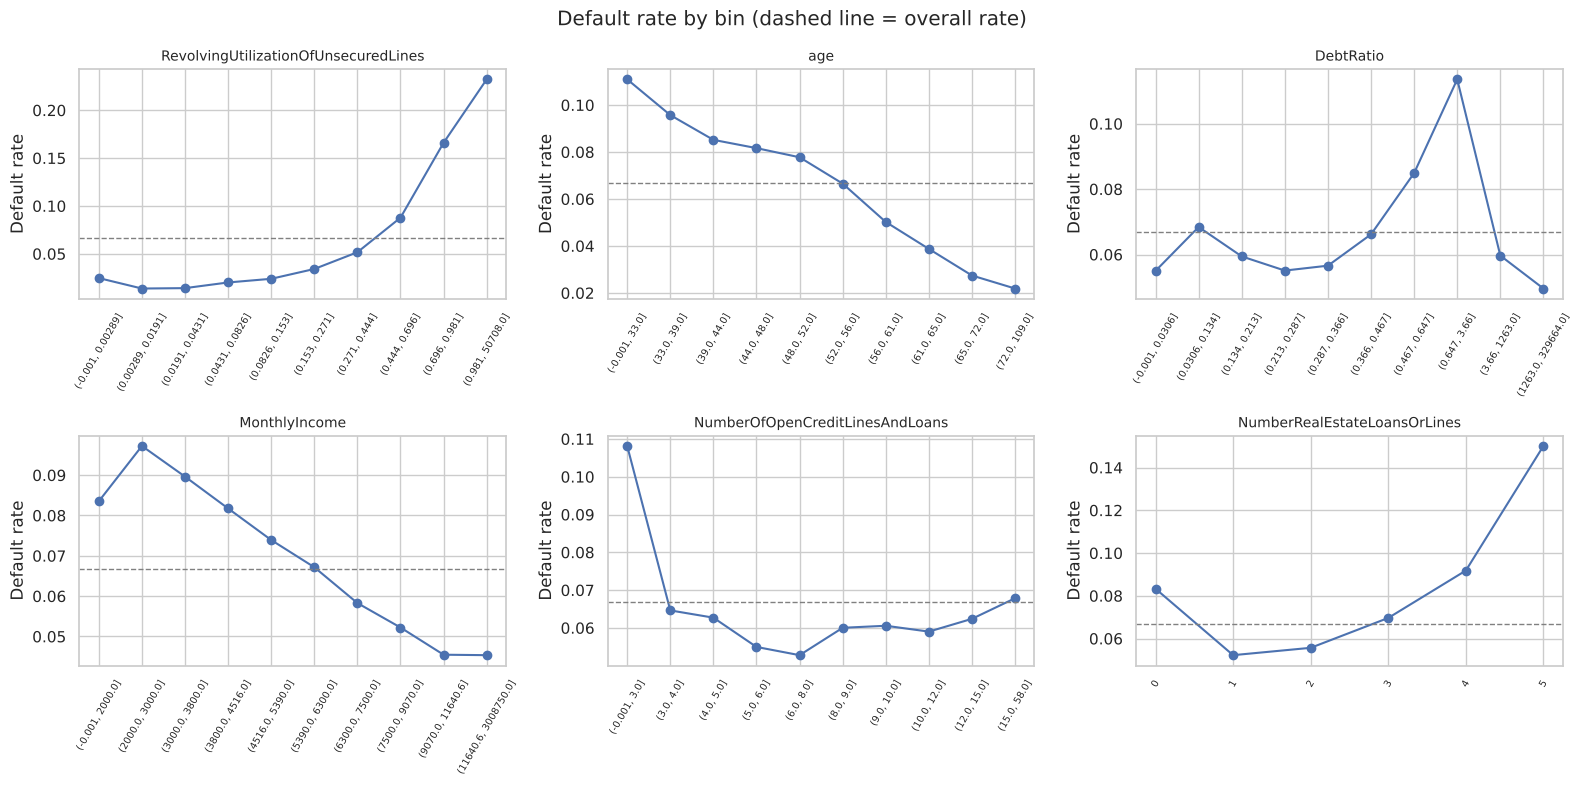

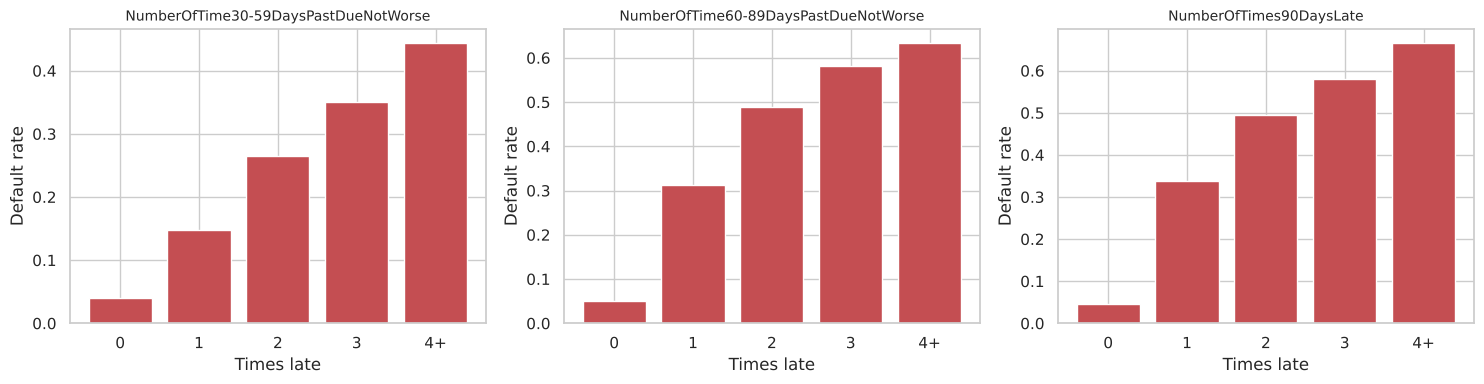

In [12]:
plot_cols = ["RevolvingUtilizationOfUnsecuredLines", "age", "DebtRatio", "MonthlyIncome",
             "NumberOfOpenCreditLinesAndLoans", "NumberRealEstateLoansOrLines"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), plot_cols):
    s = train[col]
    is_count = col == "NumberRealEstateLoansOrLines"
    groups = s.clip(upper=5) if is_count else pd.qcut(s, 10, duplicates="drop")
    r = train.groupby(groups, observed=True)[TARGET].mean()
    ax.plot(range(len(r)), r.values, marker="o")
    ax.axhline(rate, color="grey", ls="--", lw=1)
    ax.set_xticks(range(len(r)))
    ax.set_xticklabels([str(i) for i in r.index], rotation=60, fontsize=7)
    ax.set_title(col, fontsize=10); ax.set_ylabel("Default rate")
plt.suptitle("Default rate by bin (dashed line = overall rate)")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_default_rate_by_feature.png", dpi=120); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, late_cols):
    r = no_codes.groupby(no_codes[col].clip(upper=4))[TARGET].mean()
    ax.bar(r.index.astype(str), r.values, color="#C44E52")
    ax.set_xticks(range(len(r)))
    ax.set_xticklabels([*r.index.astype(str)[:-1], "4+"])
    ax.set_title(col, fontsize=10); ax.set_ylabel("Default rate"); ax.set_xlabel("Times late")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_late_payments.png", dpi=120); plt.show()

### Univariate predictive power

As a quick ranking of each variable on its own, we compute the AUC of the raw value (median-filled)
against the target. 0.5 means no signal; values below 0.5 mean the relationship is negative
(higher value, lower risk), so we also report `max(AUC, 1 - AUC)`.

In [13]:
from sklearn.metrics import roc_auc_score

rows = []
for col in train.columns.drop(TARGET):
    x = train[col].fillna(train[col].median())
    auc = roc_auc_score(train[TARGET], x)
    rows.append({"feature": col, "auc": auc, "strength": max(auc, 1 - auc),
                 "direction": "+" if auc > 0.5 else "-"})
univariate = pd.DataFrame(rows).sort_values("strength", ascending=False).reset_index(drop=True)
univariate

,feature,auc,strength,direction
0,RevolvingUtilizationOfUnsecuredLines,0.7778,0.7778,+
1,NumberOfTime30-59DaysPastDueNotWorse,0.6877,0.6877,+
2,NumberOfTimes90DaysLate,0.6581,0.6581,+
3,age,0.3684,0.6316,-
4,NumberOfTime60-89DaysPastDueNotWorse,0.6225,0.6225,+
5,MonthlyIncome,0.4302,0.5698,-
6,NumberOfDependents,0.5479,0.5479,+
7,NumberOfOpenCreditLinesAndLoans,0.4526,0.5474,-
8,NumberRealEstateLoansOrLines,0.4629,0.5371,-
9,DebtRatio,0.5222,0.5222,+


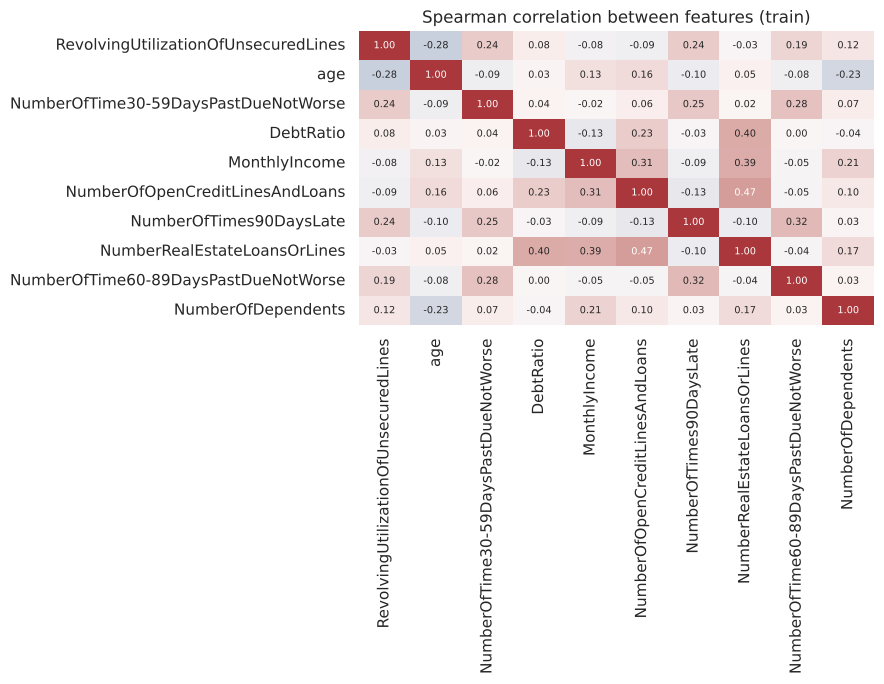

In [14]:
corr = train.drop(columns=TARGET).corr(method="spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, cbar=False, annot_kws={"size": 7})
plt.title("Spearman correlation between features (train)")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_correlation.png", dpi=120); plt.show()

**Conclusions.**

- **Revolving utilization** is the strongest single variable (univariate AUC ≈ 0.78). Default
  rises steadily from ~1–2% at low utilization to ~23% in the top decile, and peaks at ~40% for
  utilization between 1 and 2 (over the limit).
- **Past late payments** (30–59, 60–89, 90+ days) are very strong signals: one 90+ day delinquency
  raises the default rate from ~4.6% to ~34%, and risk keeps growing with each extra event. The
  three columns are strongly correlated with each other.
- **Age** has a clear negative relationship: ~11% default under 33 years vs ~2% over 72.
- **MonthlyIncome**: higher income, lower risk (~9–10% in the lowest bands vs ~4.5% at the top),
  but the effect is moderate.
- **DebtRatio** is **non-monotonic**: risk rises up to the 0.65–3.7 band (~11%) and then *drops*
  for very high values. Those very high values are mostly the rows without income (section 3), so
  the shape is an artifact of how the field was computed, not real behaviour. A tree model can
  handle this; a logistic regression needs the missing-income flag and the cap to cope with it.
- **Open credit lines** and **real-estate loans** are U-shaped: both very few (≤3 lines, 0 mortgages)
  and very many are riskier than the middle.
- **Dependents**: risk increases slightly with more dependents (~6% with 0 vs ~10% with 5+).

**What this means for modelling.**

1. Non-linear and U-shaped relationships favour a gradient-boosting model (LightGBM); the logistic
   regression baseline will need scaling and capping and will likely score lower.
2. Cleaning steps for `src/`, all fitted on the training data only: treat 96/98 as missing + flag,
   `age == 0` as missing, median imputation + missing flags for income and dependents, and
   percentile capping of utilization, DebtRatio and income.
3. Imbalance (~6.7% positives) means stratified CV, class-weight experiments, and AUC/Gini/KS/PR
   as metrics instead of accuracy.